<a href="https://colab.research.google.com/github/aishnori-abhyasi/AI-Product-Leader_Capstone/blob/main/AIPL_Capstone_AishNori_LogRegression_V1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
## !pip install matplotlib-venn
import matplotlib
## matplotlib.use('TkAgg')
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib

Preparing month over month Time-Series Data (Synthetic Data)

In [ ]:
def generate_trend_training_data (n_users=1000):
  """Simulates spending variations from the last three months"""
  np.random.seed(42)
  data = {
      'Savings_Growth_data': np.random.uniform(-3000,5000,n_users),
      'Discretionary_Spend_data': np.random.uniform(-2000,4000,n_users),
      'Utility_Bill_data': np.random.uniform(-500,1500,n_users),
      'Income_Stability_data': np.random.uniform(-2,3,n_users)
  }
  df = pd.DataFrame(data)
  df['Positive_Trend'] = (
      (df['Savings_Growth_data']>500) &
      (df['Discretionary_Spend_data']<1000)
  ).astype(int)
  return df

Training Logistic Regression Trend Part using Lasso Regression (l1)




In [ ]:
df_trend = generate_trend_training_data(1000)
X = df_trend.drop(columns=['Positive_Trend'])
y = df_trend['Positive_Trend']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
## Initialising Logistic Regression && Experimenting with Lasso Regression, so using liblinear solver for L1 normalization
trend_model = LogisticRegression(C=1.0,penalty="l1",solver='liblinear',random_state=42)
trend_model.fit(X_train,y_train)
## Saving the model
joblib.dump(trend_model,'Financial_Trend_Predictor.pkl')

['Financial_Trend_Predictor.pkl']

Extracting Coefficients for Compliance and Reason Codes

In [ ]:
print("📈 LOGISTIC REGRESSION COEFFICIENTS (TREND DIRECTION) ")
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient_Weight': trend_model.coef_[0]
}).sort_values(by='Coefficient_Weight',ascending=False)
print(coefficients)

📈 LOGISTIC REGRESSION COEFFICIENTS (TREND DIRECTION) 
                    Feature  Coefficient_Weight
0       Savings_Growth_data            0.001405
2         Utility_Bill_data            0.000150
1  Discretionary_Spend_data           -0.002211
3     Income_Stability_data           -0.094539


Training Logistic Regression Trend Part using Ridge Regression (l2)


In [ ]:
df_trend = generate_trend_training_data(1000)
X = df_trend.drop(columns=['Positive_Trend'])
y = df_trend['Positive_Trend']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
## Initialising Logistic Regression && Experimenting with Ridge Regression, so using liblinear solver for L2 normalization
trend_model = LogisticRegression(C=1.0,penalty="l2",solver='liblinear',random_state=42)
trend_model.fit(X_train,y_train)
## Saving the model
joblib.dump(trend_model,'Financial_Trend_Predictor_Ridge.pkl')

['Financial_Trend_Predictor_Ridge.pkl']

In [ ]:
print("📈 LOGISTIC REGRESSION COEFFICIENTS - RIDGE L2 Regularization(TREND DIRECTION) ")
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient_Weight': trend_model.coef_[0]
}).sort_values(by='Coefficient_Weight',ascending=False)
print(coefficients)

📈 LOGISTIC REGRESSION COEFFICIENTS - RIDGE L2 Regularization(TREND DIRECTION) 
                    Feature  Coefficient_Weight
0       Savings_Growth_data            0.001283
2         Utility_Bill_data            0.000006
1  Discretionary_Spend_data           -0.002068
3     Income_Stability_data           -0.124011


Now, after trend direction, plotting data with two major drivers

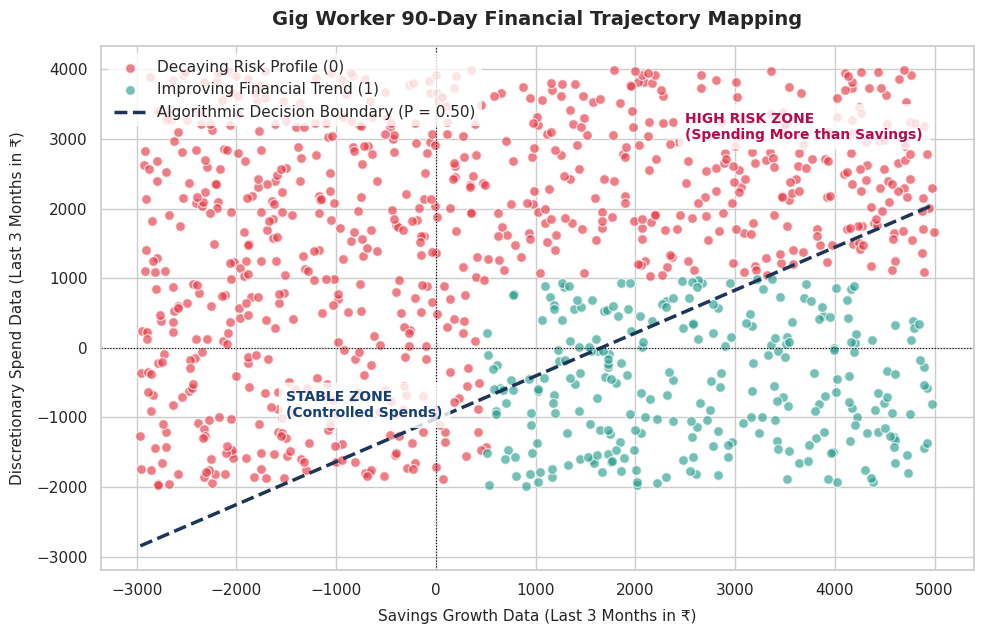

In [ ]:
np.random.seed(42)
n_users=1000
Savings_Growth_data = np.random.uniform(-3000,5000,n_users)
Discretionary_Spend_data = np.random.uniform(-2000,4000,n_users)

df_plot = pd.DataFrame({
  'Savings_Growth_data': Savings_Growth_data,
  'Discretionary_Spend_data': Discretionary_Spend_data
})

df_plot['Positive_Trend'] = (
      (df_plot['Savings_Growth_data']>500) &
      (df_plot['Discretionary_Spend_data']<1000)
  ).astype(int)

X_plot = df_plot[['Savings_Growth_data','Discretionary_Spend_data']]
y_plot = df_plot['Positive_Trend']
trend_model_2D = LogisticRegression(solver='liblinear',random_state=42)
trend_model_2D.fit(X_plot,y_plot)
plt.figure(figsize=(10, 6.5))
sns.set_theme(style="whitegrid")

# Configure font to support Unicode characters like emojis
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Apple Color Emoji', 'Segoe UI Emoji', 'Noto Color Emoji']
plt.rcParams['font.family'] = 'sans-serif'

  # Define color palette for Indian FinBuddy app
colors = {0: "#E63946", 1: "#2A9D8F"} # Red = Decaying/Risky, Green = Improving/Healthy
labels = {0: "Decaying Risk Profile (0)", 1: "Improving Financial Trend (1)"}
for category in [0,1]:
    subset = df_plot[df_plot['Positive_Trend'] == category]
    plt.scatter(
        subset['Savings_Growth_data'],
        subset['Discretionary_Spend_data'],
        c=colors[category],
        label=labels[category],
        alpha=0.65,
        edgecolors='w',
        s=50
    )
    # --- CALCULATING THE DECISION BOUNDARY LINE ---
# The boundary occurs exactly where the model outputs P = 0.50 (log-odds = 0).
# Formula: w0*x + w1*y + bias = 0  =>  y = -(w0*x + bias) / w1
b = trend_model_2D.intercept_[0]
w1, w2 = trend_model_2D.coef_[0]
x_values = np.linspace(df_plot['Savings_Growth_data'].min(), df_plot['Savings_Growth_data'].max(), 100)
y_values = -(w1 * x_values + b) / w2
# Plot the linear decision boundary separating the zones
plt.plot(x_values, y_values, color="#1D3557", linestyle="--", linewidth=2.5, label="Algorithmic Decision Boundary (P = 0.50)")
# Annotate regions to make the dashboard intuitive for risk auditors
plt.text(2500, 3000, "HIGH RISK ZONE\n(Spending More than Savings)",
    color="#B7094C", fontsize=10, fontweight='bold', bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
plt.text(-1500, -1000, "STABLE ZONE\n(Controlled Spends)",
    color="#134074", fontsize=10, fontweight='bold', bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
# Formatting Labels and Titles (Regulatory & Compliance Purpose)
plt.title("Gig Worker 90-Day Financial Trajectory Mapping", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Savings Growth Data (Last 3 Months in ₹)", fontsize=11, labelpad=8)
plt.ylabel("Discretionary Spend Data (Last 3 Months in ₹)", fontsize=11, labelpad=8)
plt.axhline(0, color='black', linewidth=0.8, linestyle=':')
plt.axvline(0, color='black', linewidth=0.8, linestyle=':')
plt.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="none")
plt.tight_layout()
  # Save image file for the CI/CD documentation registry
plt.savefig('Finance_Trend.png', dpi=300)
plt.show()

### Model Evaluation: Confusion Matrix

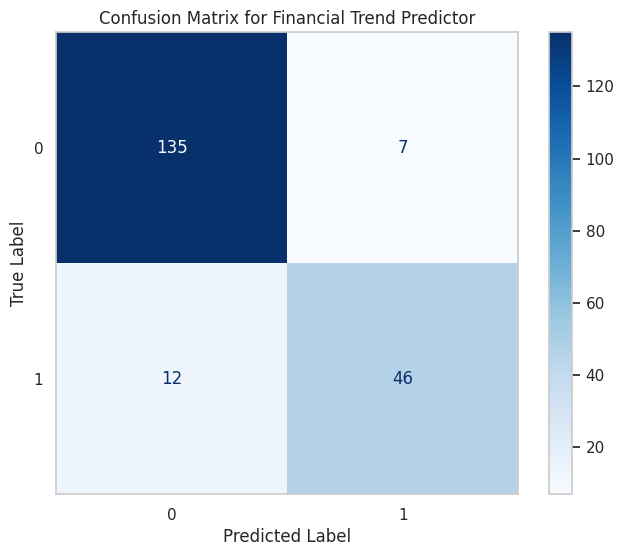

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Load the trained model
trend_model = joblib.load('Financial_Trend_Predictor.pkl')

# Predict on the test set
y_pred = trend_model.predict(X_test)

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=trend_model.classes_)

# Display the confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))
display_cm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=trend_model.classes_)
display_cm.plot(cmap='Blues', ax=ax)
plt.title('Confusion Matrix for Financial Trend Predictor')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.grid(False)
plt.show()


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import joblib
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression # Added for model training

# Ensure df_trend is generated and split for X_test, y_test
# These lines are typically run earlier, but added here for robustness
def generate_trend_training_data (n_users=1000):
  np.random.seed(42)
  data = {
      'Savings_Growth_data': np.random.uniform(-3000,5000,n_users),
      'Discretionary_Spend_data': np.random.uniform(-2000,4000,n_users),
      'Utility_Bill_data': np.random.uniform(-500,1500,n_users),
      'Income_Stability_data': np.random.uniform(-2,3,n_users)
  }
  df = pd.DataFrame(data)
  df['Positive_Trend'] = (
      (df['Savings_Growth_data']>500) &
      (df['Discretionary_Spend_data']<1000)
  ).astype(int)
  return df
df_trend = generate_trend_training_data(1000)
X = df_trend.drop(columns=['Positive_Trend'])
y = df_trend['Positive_Trend']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

# Train the model (re-added for robustness)
trend_model = LogisticRegression(C=1.0,solver='liblinear',random_state=42)
trend_model.fit(X_train,y_train)

# Save the model (re-added for robustness, though not strictly needed if we use the object directly)
joblib.dump(trend_model,'Financial_Trend_Predictor.pkl')

# Load the trained model (or just use trend_model directly, but keeping for consistency with original intent)
trend_model = joblib.load('Financial_Trend_Predictor.pkl')

# Predict on the test set
y_pred = trend_model.predict(X_test)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

Accuracy: 0.9050
Precision: 0.8679
Recall: 0.7931
F1 Score: 0.8288


**True Negatives (Top-Left, 0,0):** The model correctly predicted 135 instances as 'Decaying Risk Profile' (class 0).

**False Positives (Top-Right, 0,1):** The model incorrectly predicted 7 instances as 'Improving Financial Trend' (class 1), when they were actually 'Decaying Risk Profile' (class 0).

**False Negatives (Bottom-Left, 1,0):** The model incorrectly predicted 12 instances as 'Decaying Risk Profile' (class 0), when they were actually 'Improving Financial Trend' (class 1).

**True Positives (Bottom-Right, 1,1):** The model correctly predicted 46 instances as 'Improving Financial Trend' (class 1).

### Model Evaluation: ROC-AUC Score and Curve

ROC-AUC Score: 0.9649


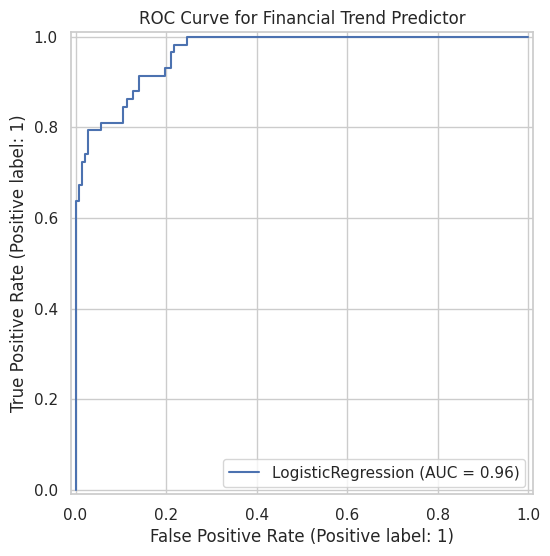

In [ ]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

# Predict probabilities for the positive class (class 1)
y_pred_proba = trend_model.predict_proba(X_test)[:, 1]

# Calculate the ROC-AUC score
roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}")

# Plot the ROC curve
fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(trend_model, X_test, y_test, ax=ax)
plt.title('ROC Curve for Financial Trend Predictor')
plt.grid(True)
plt.show()

Increasing the Test Data Percentage

In [ ]:
df_trend = generate_trend_training_data(1000)
X = df_trend.drop(columns=['Positive_Trend'])
y = df_trend['Positive_Trend']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.8,random_state=42)
## Initialising Logistic Regression
trend_model = LogisticRegression(C=1.0,solver='liblinear',random_state=42)
trend_model.fit(X_train,y_train)
## Saving the model
joblib.dump(trend_model,'Financial_Trend_Predictor.pkl')

['Financial_Trend_Predictor.pkl']

In [ ]:
print("📈 LOGISTIC REGRESSION COEFFICIENTS (TREND DIRECTION) ")
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient_Weight': trend_model.coef_[0]
}).sort_values(by='Coefficient_Weight',ascending=False)
print(coefficients)

📈 LOGISTIC REGRESSION COEFFICIENTS (TREND DIRECTION) 
                    Feature  Coefficient_Weight
0       Savings_Growth_data            0.001241
2         Utility_Bill_data           -0.000643
1  Discretionary_Spend_data           -0.001947
3     Income_Stability_data           -0.179976


Experimenting with LASSO Regression

In [ ]:
df_trend = generate_trend_training_data(1000)
X = df_trend.drop(columns=['Positive_Trend'])
y = df_trend['Positive_Trend']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
## Initialising Logistic Regression && Experimenting with Lasso Regression, so using lbfgs solver for L1 normalization
trend_model = LogisticRegression(C=1.0,solver='lbfgs',random_state=42)
trend_model.fit(X_train,y_train)
## Saving the model
joblib.dump(trend_model,'Financial_Trend_Predictor.pkl')

['Financial_Trend_Predictor.pkl']

In [ ]:
print("📈 LOGISTIC REGRESSION COEFFICIENTS (TREND DIRECTION) ")
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient_Weight': trend_model.coef_[0]
}).sort_values(by='Coefficient_Weight',ascending=False)
print(coefficients)

📈 LOGISTIC REGRESSION COEFFICIENTS (TREND DIRECTION) 
                    Feature  Coefficient_Weight
0       Savings_Growth_data            0.001435
2         Utility_Bill_data            0.000181
1  Discretionary_Spend_data           -0.002247
3     Income_Stability_data           -0.101141


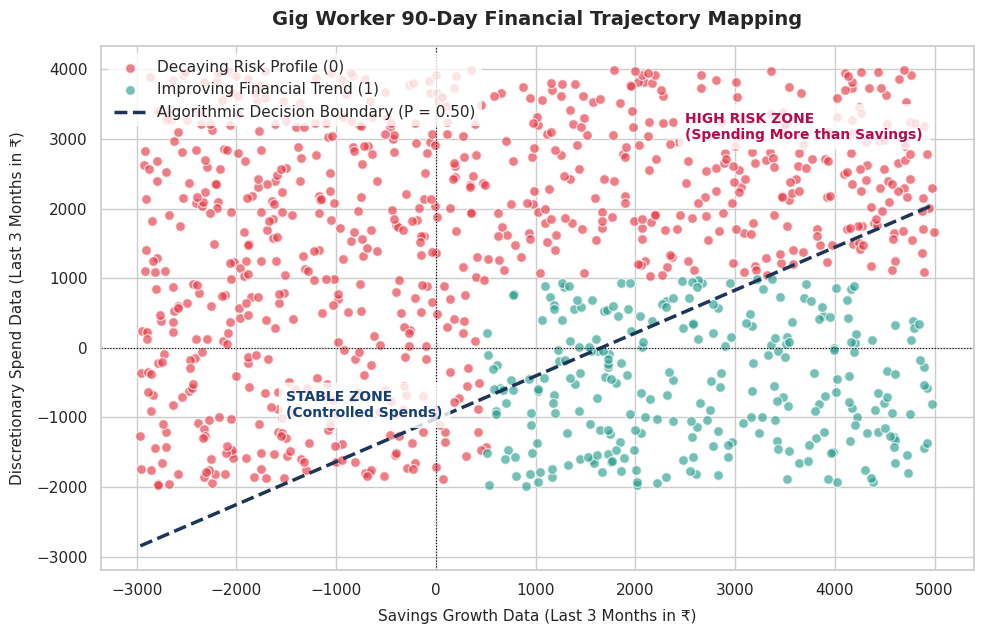

In [ ]:
np.random.seed(42)
n_users=1000
Savings_Growth_data = np.random.uniform(-3000,5000,n_users)
Discretionary_Spend_data = np.random.uniform(-2000,4000,n_users)

df_plot = pd.DataFrame({
  'Savings_Growth_data': Savings_Growth_data,
  'Discretionary_Spend_data': Discretionary_Spend_data
})

df_plot['Positive_Trend'] = (
      (df_plot['Savings_Growth_data']>500) &
      (df_plot['Discretionary_Spend_data']<1000)
  ).astype(int)

X_plot = df_plot[['Savings_Growth_data','Discretionary_Spend_data']]
y_plot = df_plot['Positive_Trend']
trend_model_2D = LogisticRegression(solver='liblinear',random_state=42)
trend_model_2D.fit(X_plot,y_plot)
plt.figure(figsize=(10, 6.5))
sns.set_theme(style="whitegrid")

# Configure font to support Unicode characters like emojis
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Apple Color Emoji', 'Segoe UI Emoji', 'Noto Color Emoji']
plt.rcParams['font.family'] = 'sans-serif'

  # Define color palette for Indian FinBuddy app
colors = {0: "#E63946", 1: "#2A9D8F"} # Red = Decaying/Risky, Green = Improving/Healthy
labels = {0: "Decaying Risk Profile (0)", 1: "Improving Financial Trend (1)"}
for category in [0,1]:
    subset = df_plot[df_plot['Positive_Trend'] == category]
    plt.scatter(
        subset['Savings_Growth_data'],
        subset['Discretionary_Spend_data'],
        c=colors[category],
        label=labels[category],
        alpha=0.65,
        edgecolors='w',
        s=50
    )
    # --- CALCULATING THE DECISION BOUNDARY LINE ---
# The boundary occurs exactly where the model outputs P = 0.50 (log-odds = 0).
# Formula: w0*x + w1*y + bias = 0  =>  y = -(w0*x + bias) / w1
b = trend_model_2D.intercept_[0]
w1, w2 = trend_model_2D.coef_[0]
x_values = np.linspace(df_plot['Savings_Growth_data'].min(), df_plot['Savings_Growth_data'].max(), 100)
y_values = -(w1 * x_values + b) / w2
# Plot the linear decision boundary separating the zones
plt.plot(x_values, y_values, color="#1D3557", linestyle="--", linewidth=2.5, label="Algorithmic Decision Boundary (P = 0.50)")
# Annotate regions to make the dashboard intuitive for risk auditors
plt.text(2500, 3000, "HIGH RISK ZONE\n(Spending More than Savings)",
    color="#B7094C", fontsize=10, fontweight='bold', bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
plt.text(-1500, -1000, "STABLE ZONE\n(Controlled Spends)",
    color="#134074", fontsize=10, fontweight='bold', bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
# Formatting Labels and Titles (Regulatory & Compliance Purpose)
plt.title("Gig Worker 90-Day Financial Trajectory Mapping", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Savings Growth Data (Last 3 Months in ₹)", fontsize=11, labelpad=8)
plt.ylabel("Discretionary Spend Data (Last 3 Months in ₹)", fontsize=11, labelpad=8)
plt.axhline(0, color='black', linewidth=0.8, linestyle=':')
plt.axvline(0, color='black', linewidth=0.8, linestyle=':')
plt.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="none")
plt.tight_layout()
  # Save image file for the CI/CD documentation registry
plt.savefig('Compliance_Trend.png', dpi=300)
plt.show()

Trying with different test percentages

In [ ]:
df_trend = generate_trend_training_data(1000)
X = df_trend.drop(columns=['Positive_Trend'])
y = df_trend['Positive_Trend']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.5,random_state=42)
## Initialising Logistic Regression && Experimenting with Lasso Regression, so using lbfgs solver for L1 normalization
trend_model = LogisticRegression(C=1.0,solver='lbfgs',random_state=42)
trend_model.fit(X_train,y_train)
## Saving the model
joblib.dump(trend_model,'Financial_Trend_Predictor.pkl')

['Financial_Trend_Predictor.pkl']

In [ ]:
print("📈 LOGISTIC REGRESSION COEFFICIENTS (TREND DIRECTION) ")
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient_Weight': trend_model.coef_[0]
}).sort_values(by='Coefficient_Weight',ascending=False)
print(coefficients)

📈 LOGISTIC REGRESSION COEFFICIENTS (TREND DIRECTION) 
                    Feature  Coefficient_Weight
0       Savings_Growth_data            0.001412
2         Utility_Bill_data            0.000359
1  Discretionary_Spend_data           -0.002211
3     Income_Stability_data           -0.054084


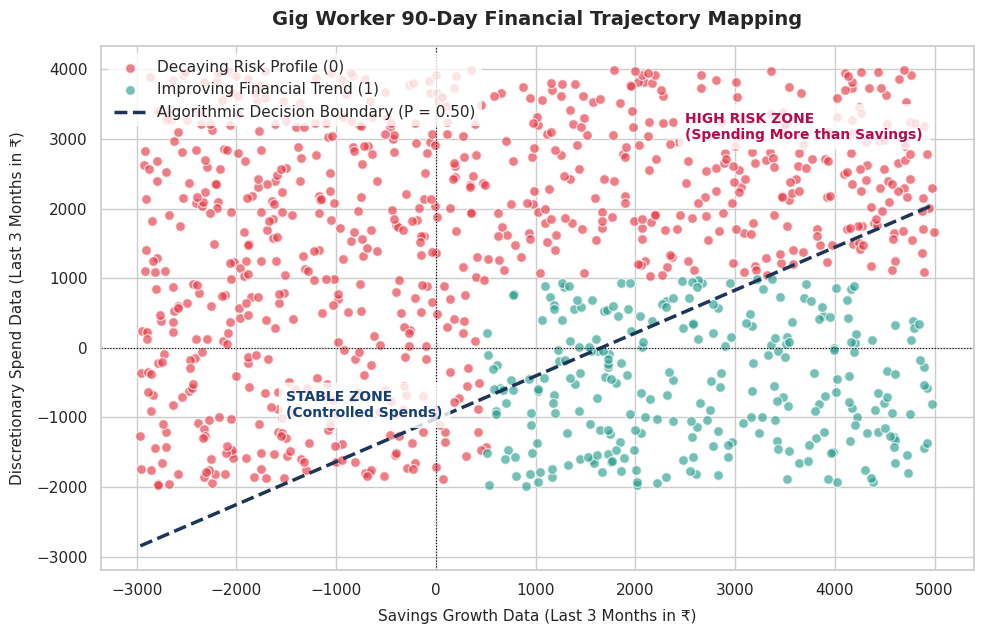

In [ ]:
np.random.seed(42)
n_users=1000
Savings_Growth_data = np.random.uniform(-3000,5000,n_users)
Discretionary_Spend_data = np.random.uniform(-2000,4000,n_users)

df_plot = pd.DataFrame({
  'Savings_Growth_data': Savings_Growth_data,
  'Discretionary_Spend_data': Discretionary_Spend_data
})

df_plot['Positive_Trend'] = (
      (df_plot['Savings_Growth_data']>500) &
      (df_plot['Discretionary_Spend_data']<1000)
  ).astype(int)

X_plot = df_plot[['Savings_Growth_data','Discretionary_Spend_data']]
y_plot = df_plot['Positive_Trend']
trend_model_2D = LogisticRegression(solver='liblinear',random_state=42)
trend_model_2D.fit(X_plot,y_plot)
plt.figure(figsize=(10, 6.5))
sns.set_theme(style="whitegrid")

# Configure font to support Unicode characters like emojis
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Apple Color Emoji', 'Segoe UI Emoji', 'Noto Color Emoji']
plt.rcParams['font.family'] = 'sans-serif'

  # Define color palette for Indian FinBuddy app
colors = {0: "#E63946", 1: "#2A9D8F"} # Red = Decaying/Risky, Green = Improving/Healthy
labels = {0: "Decaying Risk Profile (0)", 1: "Improving Financial Trend (1)"}
for category in [0,1]:
    subset = df_plot[df_plot['Positive_Trend'] == category]
    plt.scatter(
        subset['Savings_Growth_data'],
        subset['Discretionary_Spend_data'],
        c=colors[category],
        label=labels[category],
        alpha=0.65,
        edgecolors='w',
        s=50
    )
    # --- CALCULATING THE DECISION BOUNDARY LINE ---
# The boundary occurs exactly where the model outputs P = 0.50 (log-odds = 0).
# Formula: w0*x + w1*y + bias = 0  =>  y = -(w0*x + bias) / w1
b = trend_model_2D.intercept_[0]
w1, w2 = trend_model_2D.coef_[0]
x_values = np.linspace(df_plot['Savings_Growth_data'].min(), df_plot['Savings_Growth_data'].max(), 100)
y_values = -(w1 * x_values + b) / w2
# Plot the linear decision boundary separating the zones
plt.plot(x_values, y_values, color="#1D3557", linestyle="--", linewidth=2.5, label="Algorithmic Decision Boundary (P = 0.50)")
# Annotate regions to make the dashboard intuitive for risk auditors
plt.text(2500, 3000, "HIGH RISK ZONE\n(Spending More than Savings)",
    color="#B7094C", fontsize=10, fontweight='bold', bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
plt.text(-1500, -1000, "STABLE ZONE\n(Controlled Spends)",
    color="#134074", fontsize=10, fontweight='bold', bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
# Formatting Labels and Titles (Regulatory & Compliance Purpose)
plt.title("Gig Worker 90-Day Financial Trajectory Mapping", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Savings Growth Data (Last 3 Months in ₹)", fontsize=11, labelpad=8)
plt.ylabel("Discretionary Spend Data (Last 3 Months in ₹)", fontsize=11, labelpad=8)
plt.axhline(0, color='black', linewidth=0.8, linestyle=':')
plt.axvline(0, color='black', linewidth=0.8, linestyle=':')
plt.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="none")
plt.tight_layout()
  # Save image file for the CI/CD documentation registry
plt.savefig('Compliance_Trend.png', dpi=300)
plt.show()

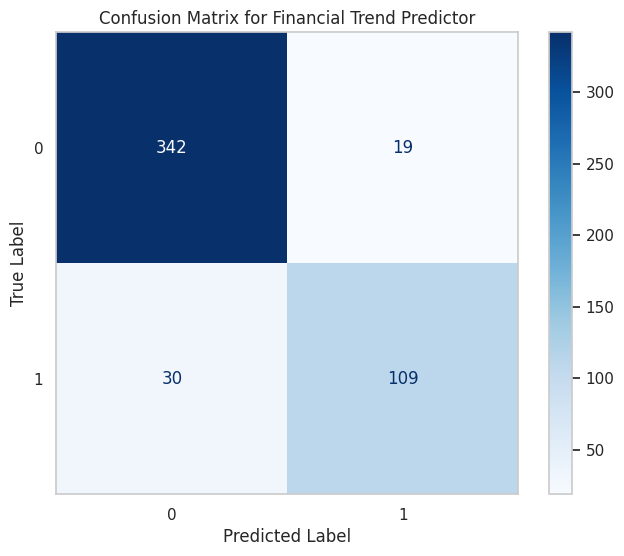

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Load the trained model
trend_model = joblib.load('Financial_Trend_Predictor.pkl')

# Predict on the test set
y_pred = trend_model.predict(X_test)

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=trend_model.classes_)

# Display the confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))
display_cm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=trend_model.classes_)
display_cm.plot(cmap='Blues', ax=ax)
plt.title('Confusion Matrix for Financial Trend Predictor')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.grid(False)
plt.show()

80 percentage test data, as there are changes noticed for Utility bill while using 20 percentage and 50 percentage

In [ ]:
df_trend = generate_trend_training_data(1000)
X = df_trend.drop(columns=['Positive_Trend'])
y = df_trend['Positive_Trend']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.8,random_state=42)
## Initialising Logistic Regression && Experimenting with Lasso Regression, so using lbfgs solver for L1 normalization
trend_model = LogisticRegression(C=1.0,solver='lbfgs',random_state=42)
trend_model.fit(X_train,y_train)
## Saving the model
joblib.dump(trend_model,'Financial_Trend_Predictor_v2.pkl')

['Financial_Trend_Predictor_v2.pkl']

In [ ]:
print("📈 LOGISTIC REGRESSION COEFFICIENTS (TREND DIRECTION) ")
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient_Weight': trend_model.coef_[0]
}).sort_values(by='Coefficient_Weight',ascending=False)
print(coefficients)

📈 LOGISTIC REGRESSION COEFFICIENTS (TREND DIRECTION) 
                    Feature  Coefficient_Weight
0       Savings_Growth_data            0.001434
2         Utility_Bill_data           -0.000443
1  Discretionary_Spend_data           -0.002163
3     Income_Stability_data           -0.145300


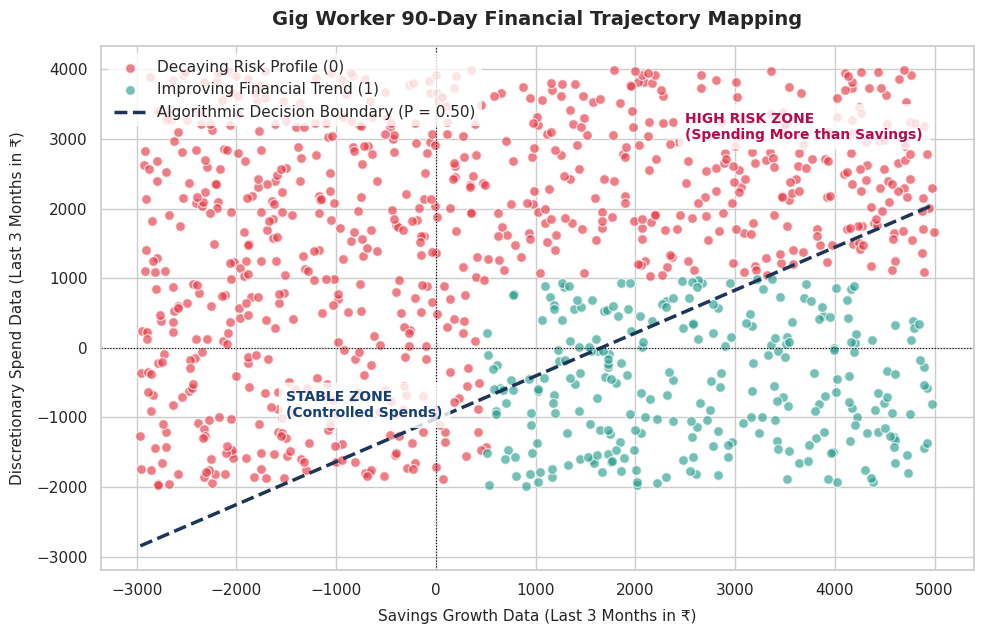

In [ ]:
np.random.seed(42)
n_users=1000
Savings_Growth_data = np.random.uniform(-3000,5000,n_users)
Discretionary_Spend_data = np.random.uniform(-2000,4000,n_users)

df_plot = pd.DataFrame({
  'Savings_Growth_data': Savings_Growth_data,
  'Discretionary_Spend_data': Discretionary_Spend_data
})

df_plot['Positive_Trend'] = (
      (df_plot['Savings_Growth_data']>500) &
      (df_plot['Discretionary_Spend_data']<1000)
  ).astype(int)

X_plot = df_plot[['Savings_Growth_data','Discretionary_Spend_data']]
y_plot = df_plot['Positive_Trend']
trend_model_2D = LogisticRegression(solver='liblinear',random_state=42)
trend_model_2D.fit(X_plot,y_plot)
plt.figure(figsize=(10, 6.5))
sns.set_theme(style="whitegrid")

# Configure font to support Unicode characters like emojis
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Apple Color Emoji', 'Segoe UI Emoji', 'Noto Color Emoji']
plt.rcParams['font.family'] = 'sans-serif'

  # Define color palette for Indian FinBuddy app
colors = {0: "#E63946", 1: "#2A9D8F"} # Red = Decaying/Risky, Green = Improving/Healthy
labels = {0: "Decaying Risk Profile (0)", 1: "Improving Financial Trend (1)"}
for category in [0,1]:
    subset = df_plot[df_plot['Positive_Trend'] == category]
    plt.scatter(
        subset['Savings_Growth_data'],
        subset['Discretionary_Spend_data'],
        c=colors[category],
        label=labels[category],
        alpha=0.65,
        edgecolors='w',
        s=50
    )
    # --- CALCULATING THE DECISION BOUNDARY LINE ---
# The boundary occurs exactly where the model outputs P = 0.50 (log-odds = 0).
# Formula: w0*x + w1*y + bias = 0  =>  y = -(w0*x + bias) / w1
b = trend_model_2D.intercept_[0]
w1, w2 = trend_model_2D.coef_[0]
x_values = np.linspace(df_plot['Savings_Growth_data'].min(), df_plot['Savings_Growth_data'].max(), 100)
y_values = -(w1 * x_values + b) / w2
# Plot the linear decision boundary separating the zones
plt.plot(x_values, y_values, color="#1D3557", linestyle="--", linewidth=2.5, label="Algorithmic Decision Boundary (P = 0.50)")
# Annotate regions to make the dashboard intuitive for risk auditors
plt.text(2500, 3000, "HIGH RISK ZONE\n(Spending More than Savings)",
    color="#B7094C", fontsize=10, fontweight='bold', bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
plt.text(-1500, -1000, "STABLE ZONE\n(Controlled Spends)",
    color="#134074", fontsize=10, fontweight='bold', bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
# Formatting Labels and Titles (Regulatory & Compliance Purpose)
plt.title("Gig Worker 90-Day Financial Trajectory Mapping", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Savings Growth Data (Last 3 Months in ₹)", fontsize=11, labelpad=8)
plt.ylabel("Discretionary Spend Data (Last 3 Months in ₹)", fontsize=11, labelpad=8)
plt.axhline(0, color='black', linewidth=0.8, linestyle=':')
plt.axvline(0, color='black', linewidth=0.8, linestyle=':')
plt.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="none")
plt.tight_layout()
  # Save image file for the CI/CD documentation registry
plt.savefig('Compliance_Trend_v2.png', dpi=300)
plt.show()

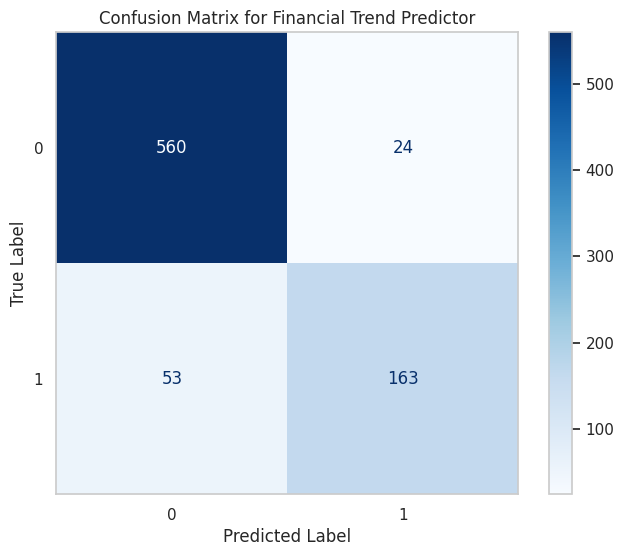

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Load the trained model
trend_model = joblib.load('Financial_Trend_Predictor_v2.pkl')

# Predict on the test set
y_pred = trend_model.predict(X_test)

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=trend_model.classes_)

# Display the confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))
display_cm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=trend_model.classes_)
display_cm.plot(cmap='Blues', ax=ax)
plt.title('Confusion Matrix for Financial Trend Predictor')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.grid(False)
plt.show()

ROC-AUC Score: 0.9648


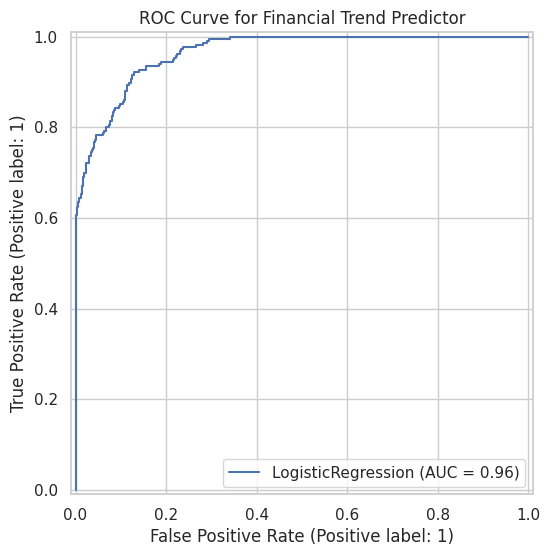

In [ ]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

# Predict probabilities for the positive class (class 1)
y_pred_proba = trend_model.predict_proba(X_test)[:, 1]

# Calculate the ROC-AUC score
roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}")

# Plot the ROC curve
fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(trend_model, X_test, y_test, ax=ax)
plt.title('ROC Curve for Financial Trend Predictor')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import joblib
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression # Added for model training

# Ensure df_trend is generated and split for X_test, y_test
# These lines are typically run earlier, but added here for robustness
def generate_trend_training_data (n_users=1000):
  np.random.seed(42)
  data = {
      'Savings_Growth_data': np.random.uniform(-3000,5000,n_users),
      'Discretionary_Spend_data': np.random.uniform(-2000,4000,n_users),
      'Utility_Bill_data': np.random.uniform(-500,1500,n_users),
      'Income_Stability_data': np.random.uniform(-2,3,n_users)
  }
  df = pd.DataFrame(data)
  df['Positive_Trend'] = (
      (df['Savings_Growth_data']>500) &
      (df['Discretionary_Spend_data']<1000)
  ).astype(int)
  return df
df_trend = generate_trend_training_data(1000)
X = df_trend.drop(columns=['Positive_Trend'])
y = df_trend['Positive_Trend']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.8,random_state=42)

# Train the model (re-added for robustness)
trend_model = LogisticRegression(C=1.0,solver='lbfgs',random_state=42)
trend_model.fit(X_train,y_train)

# Save the model (re-added for robustness, though not strictly needed if we use the object directly)
joblib.dump(trend_model,'Financial_Trend_Predictor_v2.pkl')

# Load the trained model (or just use trend_model directly, but keeping for consistency with original intent)
trend_model = joblib.load('Financial_Trend_Predictor_v2.pkl')

# Predict on the test set
y_pred = trend_model.predict(X_test)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

Accuracy: 0.9038
Precision: 0.8717
Recall: 0.7546
F1 Score: 0.8089
